# Clustering and Association Rule Mining

## Objective
To understand and implement clustering and association
rule mining algorithms using real-world datasets.

## Algorithms Used
1. K-Means Clustering
2. Hierarchical Clustering
3. DBSCAN
4. Apriori
5. FP-Growth

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
df = pd.read_csv("Mall_Customers.csv")


In [7]:
df.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [8]:
df.tail(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
190,191,Female,34,103,23
191,192,Female,32,103,69
192,193,Male,33,113,8
193,194,Female,38,113,91
194,195,Female,47,120,16
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


In [9]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 200
Columns: 5


In [10]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [11]:
df.describe(include='all')

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


In [12]:
print(df.isnull().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [13]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


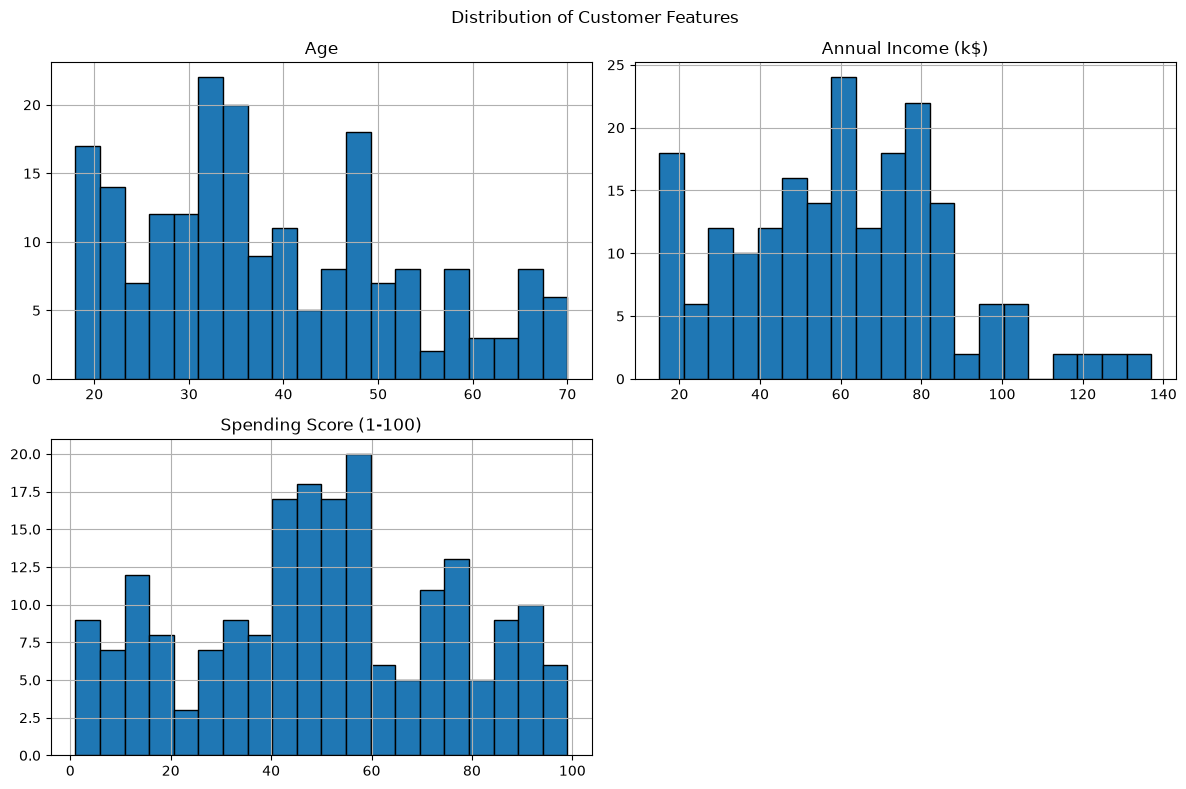

In [14]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

df[features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Distribution of Customer Features")
plt.tight_layout()
plt.show()

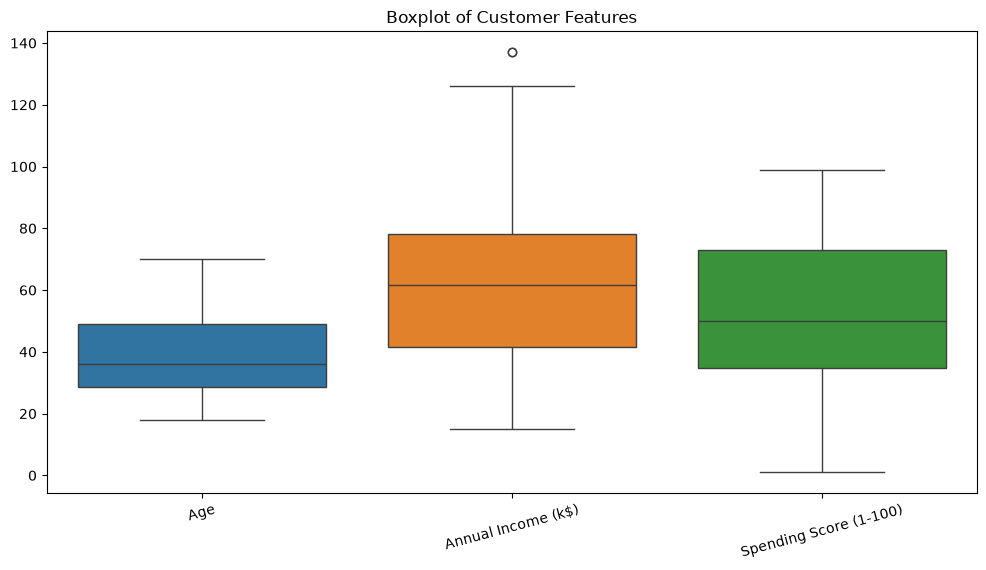

In [15]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[features])

plt.title("Boxplot of Customer Features")
plt.xticks(rotation=15)
plt.show()

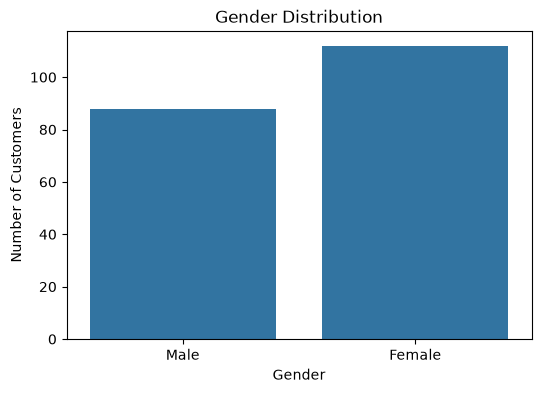

In [16]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Gender')

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [18]:
data = df.copy()

print("Dataset copied successfully!")
print("Dataset Shape:", data.shape)

Dataset copied successfully!
Dataset Shape: (200, 5)


In [19]:
data = data.drop(columns=['CustomerID'])

print("CustomerID column removed successfully!")
print(data.head())

CustomerID column removed successfully!
   Gender  Age  Annual Income (k$)  Spending Score (1-100)
0    Male   19                  15                      39
1    Male   21                  15                      81
2  Female   20                  16                       6
3  Female   23                  16                      77
4  Female   31                  17                      40


In [20]:
print(data.isnull().sum())

Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [21]:
print("Total Missing Values:", data.isnull().sum().sum())

Total Missing Values: 0


In [23]:
for col in data.columns:

    if data[col].isnull().sum() > 0:

        if data[col].dtype == 'object':
            data[col] = data[col].fillna(data[col].mode()[0])

        else:
            data[col] = data[col].fillna(data[col].median())



In [24]:
print(data.isnull().sum())

Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [25]:
features = [
    'Age',
    'Annual Income (k$)',
    'Spending Score (1-100)'
]

X = data[features]

print(X.head())

   Age  Annual Income (k$)  Spending Score (1-100)
0   19                  15                      39
1   21                  15                      81
2   20                  16                       6
3   23                  16                      77
4   31                  17                      40


In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


In [28]:
X_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

print(X_scaled.head())

        Age  Annual Income (k$)  Spending Score (1-100)
0 -1.424569           -1.738999               -0.434801
1 -1.281035           -1.738999                1.195704
2 -1.352802           -1.700830               -1.715913
3 -1.137502           -1.700830                1.040418
4 -0.563369           -1.662660               -0.395980


In [29]:
print("Mean of Scaled Features:")
print(X_scaled.mean())

print("\nStandard Deviation:")
print(X_scaled.std())

Mean of Scaled Features:
Age                      -1.021405e-16
Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64

Standard Deviation:
Age                       1.002509
Annual Income (k$)        1.002509
Spending Score (1-100)    1.002509
dtype: float64


In [30]:
from sklearn.cluster import KMeans

In [31]:
wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

print("WCSS values:", wcss)

WCSS values: [600.0, 389.3861889564372, 295.2122461555489, 205.22514747675913, 168.24758017556837, 133.86842085478855, 117.01155455889813, 103.87329152383714, 93.09289110041726, 82.38515364526599]


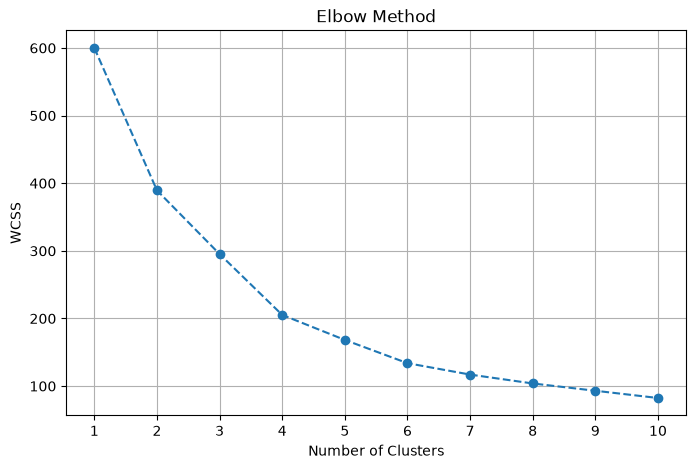

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o',
    linestyle='--'
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [37]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

In [38]:
data['Cluster'] = clusters

print(data.head(10))

   Gender  Age  Annual Income (k$)  Spending Score (1-100)  Cluster
0    Male   19                  15                      39        2
1    Male   21                  15                      81        2
2  Female   20                  16                       6        2
3  Female   23                  16                      77        2
4  Female   31                  17                      40        2
5  Female   22                  17                      76        2
6  Female   35                  18                       6        0
7  Female   23                  18                      94        2
8    Male   64                  19                       3        0
9  Female   30                  19                      72        2


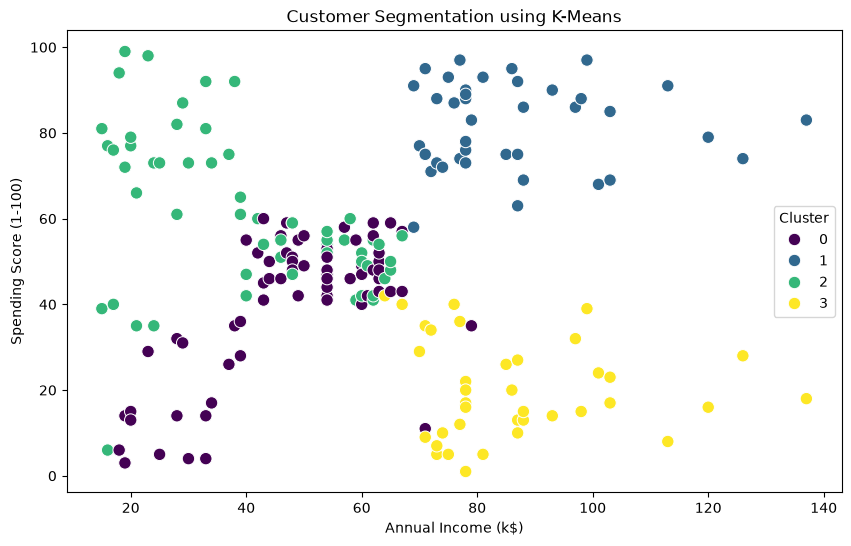

In [39]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=data['Annual Income (k$)'],
    y=data['Spending Score (1-100)'],
    hue=data['Cluster'],
    palette='viridis',
    s=80
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

In [40]:
print(data['Cluster'].value_counts().sort_index())

Cluster
0    65
1    40
2    57
3    38
Name: count, dtype: int64


In [41]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

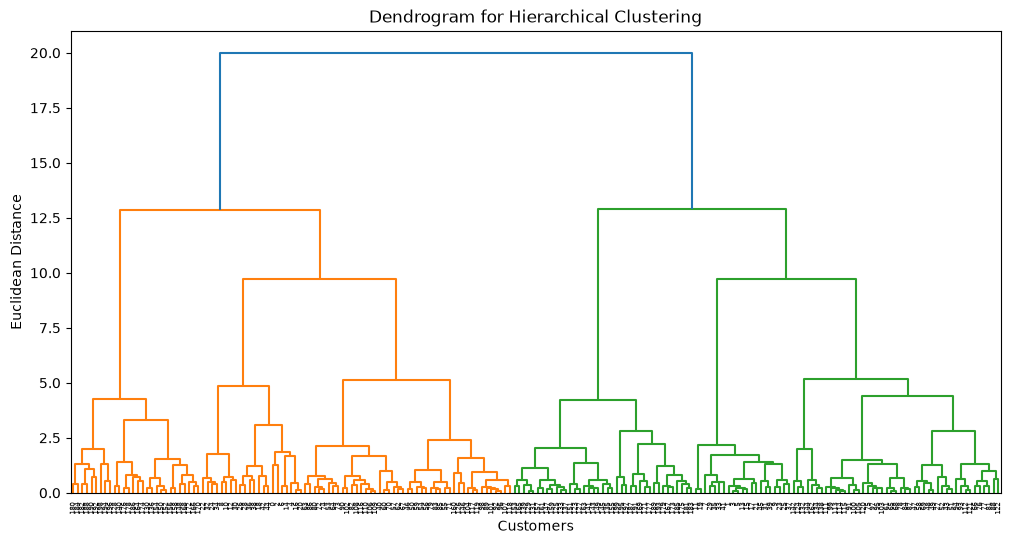

In [42]:
plt.figure(figsize=(12, 6))

linked = linkage(X_scaled, method='ward')

dendrogram(linked)

plt.title("Dendrogram for Hierarchical Clustering")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")

plt.show()

In [44]:
hc_model = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

hc_clusters = hc_model.fit_predict(X_scaled)


In [45]:
data['Hierarchical_Cluster'] = hc_clusters

print(data.head(10))

   Gender  Age  Annual Income (k$)  Spending Score (1-100)  Cluster  \
0    Male   19                  15                      39        2   
1    Male   21                  15                      81        2   
2  Female   20                  16                       6        2   
3  Female   23                  16                      77        2   
4  Female   31                  17                      40        2   
5  Female   22                  17                      76        2   
6  Female   35                  18                       6        0   
7  Female   23                  18                      94        2   
8    Male   64                  19                       3        0   
9  Female   30                  19                      72        2   

   Hierarchical_Cluster  
0                     0  
1                     1  
2                     0  
3                     1  
4                     0  
5                     1  
6                     0  
7         

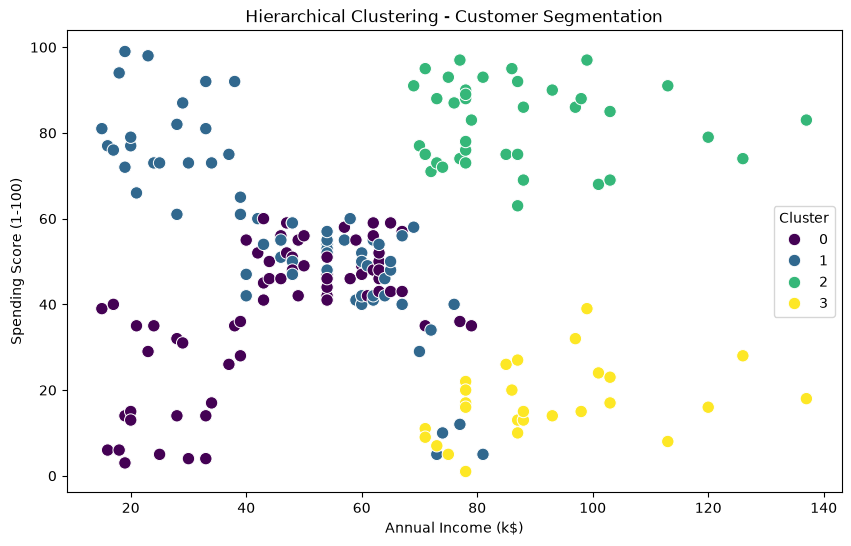

In [46]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=data['Annual Income (k$)'],
    y=data['Spending Score (1-100)'],
    hue=data['Hierarchical_Cluster'],
    palette='viridis',
    s=80
)

plt.title("Hierarchical Clustering - Customer Segmentation")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

In [47]:
print("K-Means Cluster Count:")
print(data['Cluster'].value_counts().sort_index())

print("\nHierarchical Cluster Count:")
print(data['Hierarchical_Cluster'].value_counts().sort_index())

K-Means Cluster Count:
Cluster
0    65
1    40
2    57
3    38
Name: count, dtype: int64

Hierarchical Cluster Count:
Hierarchical_Cluster
0    67
1    66
2    39
3    28
Name: count, dtype: int64


In [48]:
from sklearn.cluster import DBSCAN

In [49]:
dbscan_model = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_clusters = dbscan_model.fit_predict(X_scaled)

In [50]:
data['DBSCAN_Cluster'] = dbscan_clusters

print(data[['Age', 'Annual Income (k$)',
            'Spending Score (1-100)',
            'DBSCAN_Cluster']].head(10))

   Age  Annual Income (k$)  Spending Score (1-100)  DBSCAN_Cluster
0   19                  15                      39              -1
1   21                  15                      81               0
2   20                  16                       6              -1
3   23                  16                      77               0
4   31                  17                      40              -1
5   22                  17                      76               0
6   35                  18                       6              -1
7   23                  18                      94              -1
8   64                  19                       3              -1
9   30                  19                      72               0


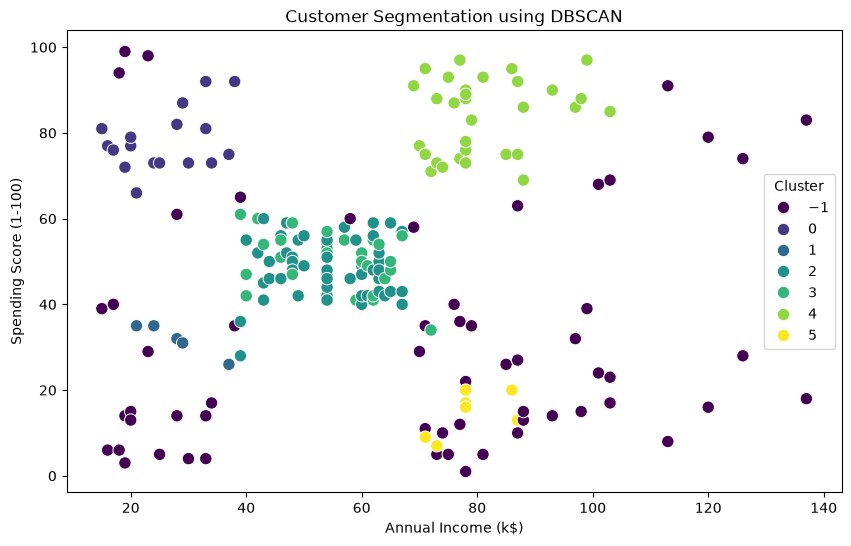

In [51]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=data['Annual Income (k$)'],
    y=data['Spending Score (1-100)'],
    hue=data['DBSCAN_Cluster'],
    palette='viridis',
    s=80
)

plt.title("Customer Segmentation using DBSCAN")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

In [52]:
print("DBSCAN Cluster Analysis")

print(data['DBSCAN_Cluster'].value_counts().sort_index())

n_clusters = len(set(dbscan_clusters)) - (
    1 if -1 in dbscan_clusters else 0
)

n_noise = list(dbscan_clusters).count(-1)

print("\nNumber of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

DBSCAN Cluster Analysis
DBSCAN_Cluster
-1    60
 0    17
 1     5
 2    51
 3    28
 4    32
 5     7
Name: count, dtype: int64

Number of Clusters: 6
Number of Noise Points: 60


In [53]:
print("K-Means Clusters:",
      len(set(clusters)))

print("Hierarchical Clusters:",
      len(set(hc_clusters)))

print("DBSCAN Clusters:",
      n_clusters)

print("DBSCAN Noise Points:",
      n_noise)

K-Means Clusters: 4
Hierarchical Clusters: 4
DBSCAN Clusters: 6
DBSCAN Noise Points: 60


In [55]:
!pip install mlxtend

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 1.8 MB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 2.1 MB/s eta 0:00:01
   -------------------------------------- - 1.3/1.4 MB 1.7 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 1.7 MB/s  0:00:00



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\kumar\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [56]:
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

In [58]:
groceries = pd.read_csv("Groceries_dataset.csv")

In [59]:
groceries.head(10)

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk
5,4941,14-02-2015,rolls/buns
6,4501,08-05-2015,other vegetables
7,3803,23-12-2015,pot plants
8,2762,20-03-2015,whole milk
9,4119,12-02-2015,tropical fruit


In [60]:
groceries.tail(10)

,Member_number,Date,itemDescription
38755,4586,26-09-2014,bottled water
38756,1987,29-10-2014,fruit/vegetable juice
38757,4376,07-12-2014,rolls/buns
38758,2511,18-06-2014,long life bakery product
38759,3364,06-05-2014,oil
38760,4471,08-10-2014,sliced cheese
38761,2022,23-02-2014,candy
38762,1097,16-04-2014,cake bar
38763,1510,03-12-2014,fruit/vegetable juice
38764,1521,26-12-2014,cat food


In [62]:
groceries.info()

<class 'pandas.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Member_number    38765 non-null  int64
 1   Date             38765 non-null  str  
 2   itemDescription  38765 non-null  str  
dtypes: int64(1), str(2)
memory usage: 908.7 KB


In [63]:
print(groceries.isnull().sum())

print("Total Missing Values:",
      groceries.isnull().sum().sum())

Member_number      0
Date               0
itemDescription    0
dtype: int64
Total Missing Values: 0


In [64]:
print(groceries.columns)

Index(['Member_number', 'Date', 'itemDescription'], dtype='str')


In [65]:
print(groceries.columns)
print(groceries.head())

Index(['Member_number', 'Date', 'itemDescription'], dtype='str')
   Member_number        Date   itemDescription
0           1808  21-07-2015    tropical fruit
1           2552  05-01-2015        whole milk
2           2300  19-09-2015         pip fruit
3           1187  12-12-2015  other vegetables
4           3037  01-02-2015        whole milk


In [66]:
transactions = groceries.groupby(
    ['Member_number', 'Date']
)['itemDescription'].apply(list)

print(transactions.head())

Member_number  Date      
1000           15-03-2015    [sausage, whole milk, semi-finished bread, yog...
               24-06-2014                    [whole milk, pastry, salty snack]
               24-07-2015                       [canned beer, misc. beverages]
               25-11-2015                          [sausage, hygiene articles]
               27-05-2015                           [soda, pickled vegetables]
Name: itemDescription, dtype: object


In [67]:
transaction_list = transactions.tolist()

print("Total Transactions:", len(transaction_list))

print("\nFirst 5 Transactions:")
for i in transaction_list[:5]:
    print(i)

Total Transactions: 14963

First 5 Transactions:
['sausage', 'whole milk', 'semi-finished bread', 'yogurt']
['whole milk', 'pastry', 'salty snack']
['canned beer', 'misc. beverages']
['sausage', 'hygiene articles']
['soda', 'pickled vegetables']


In [72]:
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()

te_array = te.fit(transaction_list).transform(transaction_list)

basket = pd.DataFrame(
    te_array,
    columns=te.columns_
)
basket.head()

,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [70]:
print("Basket Shape:", basket.shape)

print("\nTotal Products:", len(basket.columns))

print("\nTotal Transactions:", len(basket))

Basket Shape: (14963, 167)

Total Products: 167

Total Transactions: 14963


In [73]:
from mlxtend.frequent_patterns import apriori, association_rules
import time

In [74]:
start_time = time.time()

frequent_itemsets_apriori = apriori(
    basket,
    min_support=0.01,
    use_colnames=True
)

apriori_time = time.time() - start_time

print("Apriori Algorithm Completed Successfully!")
print("Execution Time:", apriori_time, "seconds")

Apriori Algorithm Completed Successfully!
Execution Time: 0.24815583229064941 seconds


In [75]:
frequent_itemsets_apriori.head(10)

,support,itemsets
0,0.021386,frozenset({UHT-milk})
1,0.033950,frozenset({beef})
2,0.021787,frozenset({berries})
3,0.016574,frozenset({beverages})
4,0.045312,frozenset({bottled beer})
5,0.060683,frozenset({bottled water})
6,0.037626,frozenset({brown bread})
7,0.035220,frozenset({butter})
8,0.017577,frozenset({butter milk})
9,0.014369,frozenset({candy})


In [80]:
rules_apriori = association_rules(
    frequent_itemsets_apriori,
    metric="confidence",
    min_threshold=0.1
)

In [78]:
rules_apriori[
    ['antecedents', 'consequents',
     'support', 'confidence', 'lift']
].head(10)

,antecedents,consequents,support,confidence,lift
0,frozenset({other vegetables}),frozenset({whole milk}),0.014837,0.121511,0.769430
1,frozenset({rolls/buns}),frozenset({whole milk}),0.013968,0.126974,0.804028
2,frozenset({soda}),frozenset({whole milk}),0.011629,0.119752,0.758296
3,frozenset({yogurt}),frozenset({whole milk}),0.011161,0.129961,0.822940


In [81]:
print("Total Frequent Itemsets:",
      len(frequent_itemsets_apriori))

print("Total Association Rules:",
      len(rules_apriori))

print("Apriori Execution Time:",
      apriori_time, "seconds")

Total Frequent Itemsets: 69
Total Association Rules: 4
Apriori Execution Time: 0.24815583229064941 seconds


In [84]:
start_time = time.time()

frequent_itemsets_fp = fpgrowth(
    basket,
    min_support=0.01,
    use_colnames=True
)

fp_time = time.time() - start_time

print("Execution Time:", fp_time, "seconds")

Execution Time: 0.3924694061279297 seconds


In [83]:
frequent_itemsets_fp.head(10)

,support,itemsets
0,0.157923,frozenset({whole milk})
1,0.085879,frozenset({yogurt})
2,0.060349,frozenset({sausage})
3,0.051728,frozenset({pastry})
4,0.018780,frozenset({salty snack})
5,0.046916,frozenset({canned beer})
6,0.015772,frozenset({misc. beverages})
7,0.013700,frozenset({hygiene articles})
8,0.097106,frozenset({soda})
9,0.037760,frozenset({frankfurter})


In [85]:
rules_fp = association_rules(
    frequent_itemsets_fp,
    metric="confidence",
    min_threshold=0.1
)

In [88]:
rules_fp[
    ['antecedents', 'consequents',
     'support', 'confidence', 'lift']
].head(10)

,antecedents,consequents,support,confidence,lift
0,frozenset({yogurt}),frozenset({whole milk}),0.011161,0.129961,0.822940
1,frozenset({soda}),frozenset({whole milk}),0.011629,0.119752,0.758296
2,frozenset({rolls/buns}),frozenset({whole milk}),0.013968,0.126974,0.804028
3,frozenset({other vegetables}),frozenset({whole milk}),0.014837,0.121511,0.769430


In [89]:
print("Total Frequent Itemsets:",
      len(frequent_itemsets_fp))

print("Total Association Rules:",
      len(rules_fp))

print("FP-Growth Execution Time:",
      fp_time, "seconds")

Total Frequent Itemsets: 69
Total Association Rules: 4
FP-Growth Execution Time: 0.3924694061279297 seconds


In [90]:
comparison = pd.DataFrame({
    'Algorithm': ['Apriori', 'FP-Growth'],

    'Frequent Itemsets': [
        len(frequent_itemsets_apriori),
        len(frequent_itemsets_fp)
    ],

    'Association Rules': [
        len(rules_apriori),
        len(rules_fp)
    ],

    'Average Support': [
        rules_apriori['support'].mean(),
        rules_fp['support'].mean()
    ],

    'Average Confidence': [
        rules_apriori['confidence'].mean(),
        rules_fp['confidence'].mean()
    ],

    'Average Lift': [
        rules_apriori['lift'].mean(),
        rules_fp['lift'].mean()
    ],

    'Execution Time': [
        apriori_time,
        fp_time
    ]
})

comparison

,Algorithm,Frequent Itemsets,Association Rules,Average Support,Average Confidence,Average Lift,Execution Time
0,Apriori,69,4,0.012898,0.12455,0.788674,0.248156
1,FP-Growth,69,4,0.012898,0.12455,0.788674,0.392469


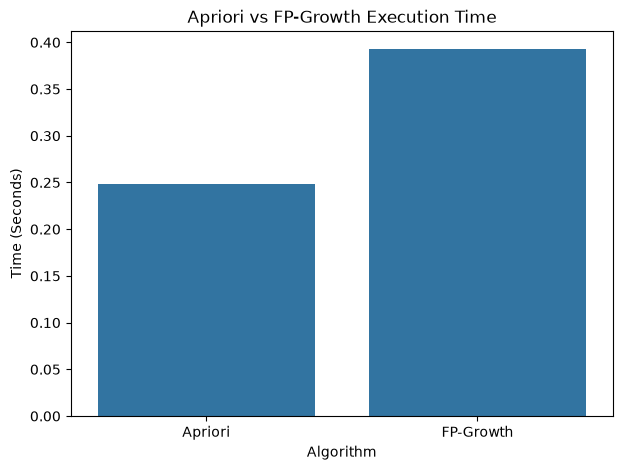

In [91]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=comparison,
    x='Algorithm',
    y='Execution Time'
)

plt.title("Apriori vs FP-Growth Execution Time")
plt.ylabel("Time (Seconds)")
plt.show()

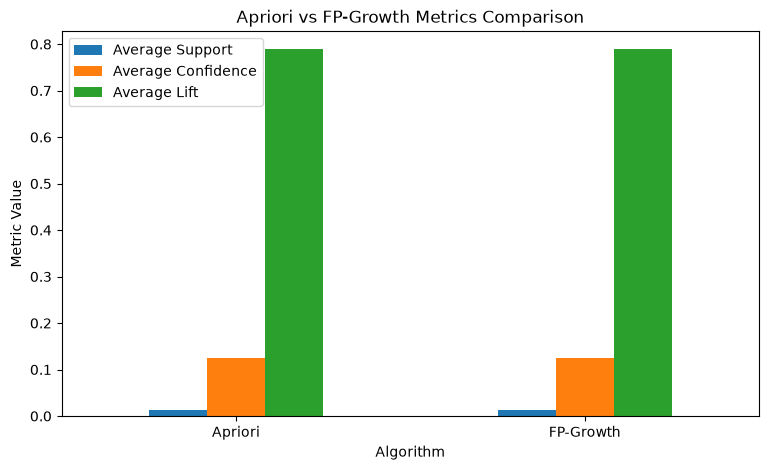

In [92]:
comparison.set_index('Algorithm')[
    ['Average Support', 'Average Confidence', 'Average Lift']
].plot(kind='bar', figsize=(9, 5))

plt.title("Apriori vs FP-Growth Metrics Comparison")
plt.ylabel("Metric Value")
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [94]:
apriori_report = rules_apriori.copy()
apriori_report['Algorithm'] = 'Apriori'

fp_report = rules_fp.copy()
fp_report['Algorithm'] = 'FP-Growth'

association_report = pd.concat(
    [apriori_report, fp_report],
    ignore_index=True
)

association_report.to_csv(
    "Association_Rule_Report.csv",
    index=False
)

In [ ]:
## Conclusion

In this practical i learned about Clustering and Association Rule Mining using two different datasets.

First, we used the Mall Customer Segmentation Dataset. We cleaned the data and applied feature scaling. Then we implemented K-Means, Hierarchical Clustering and DBSCAN algorithms. Using the Elbow Method, we selected 4 clusters for K-Means. Hierarchical Clustering also created 4 clusters, while DBSCAN found 6 clusters and 60 noise points.

Next, we used the Groceries Dataset to find products that were purchased together. We implemented Apriori and FP-Growth algorithms and generated association rules. Both algorithms produced 69 frequent itemsets and 4 association rules.

We also compared Support, Confidence, Lift and Execution Time. In our results, Apriori took 0.248 seconds, while FP-Growth took 0.392 seconds.

Through this practical, we learned how to group customers and find shopping patterns using Machine Learning algorithms.